In [1]:
import numpy as np
import matplotlib.pyplot as plt
from bat_hd.random_walk import generate_bat_flight
from bat_hd.bat_hd_visual_attractor import (
    BatToroidalHDModel,BatToroidalHDConfig
)
from bat_hd.plot_tools import angular_error, smooth_ts
import os
from concurrent.futures import ThreadPoolExecutor

DATA_DIR = "../simulation_data/hebb_alt"
PLOTS_DIR = "../plots/hebb_alt"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

In [2]:
T = 400
dt = 0.5e-3
n = (256, 128)
intrinsic_noise = 0.02
input_noise = 0
n_conj = (20,10)
n_landmarks = 40
interval = 1000
rng = np.random.default_rng(seed=0)



bat_flight = generate_bat_flight(T=T, dt=dt)


cfg = BatToroidalHDConfig(
    n_yaw=256,
    n_pitch=128,
    n_conj_yaw=32,
    n_conj_pitch=16,
    n_landmarks=20,
    seed=1,
    ring_noise=intrinsic_noise,
    conj_noise=intrinsic_noise,
)
model = BatToroidalHDModel(cfg)
model.warm_up(yaw_deg=bat_flight["dir_torus"][0,0], pitch_deg=bat_flight["dir_torus"][0,1], n_steps=500)
result = model.run(bat_flight["dir_vel"],bat_flight["dir_sphere"], record_every=interval)


Simulating: 100%|██████████| 800000/800000 [07:07<00:00, 1869.17it/s]


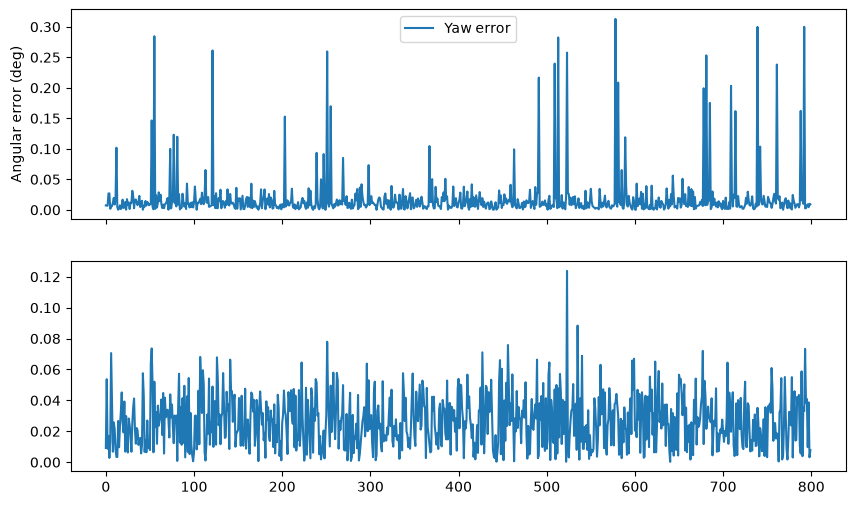

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axs[0].plot(np.abs(angular_error(result["decoded_angle"][:,0], bat_flight["dir_torus"][::interval,0])), label="Yaw error")
axs[1].plot(np.abs(angular_error(result["decoded_angle"][:,1], bat_flight["dir_torus"][::interval,1])), label="Pitch error")
axs[0].set_ylabel("Angular error (deg)")
axs[0].legend()
